## Drainage Analysis

In [1]:
# Import necessary modules for the drainage area analysis
import geopandas as gpd
import rasterio
import rasterio.mask
import pystac_client
import planetary_computer
import stackstac
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
#Load Tokyo Prefecture shapefile and inspect the data
tokyo_shapefile = gpd.read_file('tokyo_prefecture_limits/N03-20260101_13.shp')
tokyo_shapefile.columns

Index(['N03_001', 'N03_002', 'N03_003', 'N03_004', 'N03_005', 'N03_007',
       'geometry'],
      dtype='object')

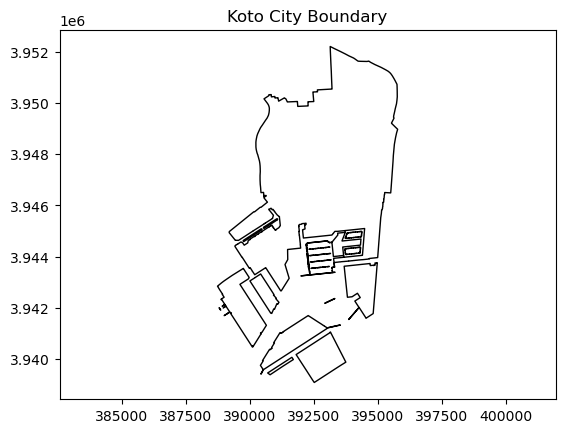

In [3]:
#Load koto city data and transform to crs
koto_city = tokyo_shapefile[(tokyo_shapefile["N03_004"] == "江東区") | (tokyo_shapefile['N03_007'] == '13108')].copy()
koto_city = koto_city.to_crs(epsg=32654)  # Transform to EPSG:32654 coordinate reference system
koto_city['area'] = koto_city.geometry.area / 1000000  # Calculate the area of the geometry in square kilometers

# print(koto_city[['N03_004', 'N03_007', 'area']])  # Display the relevant columns of the koto_city GeoDataFrame
koto_city.plot(edgecolor="black", facecolor="none")
plt.title("Koto City Boundary")
plt.axis("equal")
plt.show()

In [4]:
#Get the bounding box of Koto City in WGS84 coordinates
koto_wgs84 = koto_city.to_crs(epsg=4326)  # Transform to WGS84 coordinate reference system
koto_geometry = koto_wgs84.geometry.union_all()
koto_bbox = tuple(koto_wgs84.total_bounds)  # Get the bounding box of Koto City in WGS84 coordinates

In [5]:
#Connecting to the Planetary Computer STAC API and searching for Sentinel-2 imagery for Koto City
catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1")

# Search for Sentinel-2 imagery within the bounding box of Koto City
search = catalog.search(collections=["sentinel-2-l2a"],bbox=koto_bbox, 
                        datetime="2020-01-01/2020-12-31", query={"eo:cloud_cover": {"lt": 15}})

items = search.item_collection()

In [6]:
#Signing assets for access to the Planetary Computer
signed_items = [planetary_computer.sign(item) for item in items]
#Loading spectral bands
bands = ["B02", "B03", "B04", "B08", "B11", "B12"]  # Blue, Green, Red, NIR bands, and SWIR bands

image_stack = stackstac.stack(signed_items, assets=bands, epsg=32654, resolution=10, 
                              bounds_latlon=koto_bbox)

In [7]:
koto_projected = koto_city.to_crs(epsg=32654)  # Transform Koto City geometry to match the image stack CRS  

In [8]:
#cloud filtered composite of the Sentinel-2 imagery for Koto City
composite = image_stack.median(dim="time", skipna=True).compute()

print(composite.shape)

(6, 1322, 712)


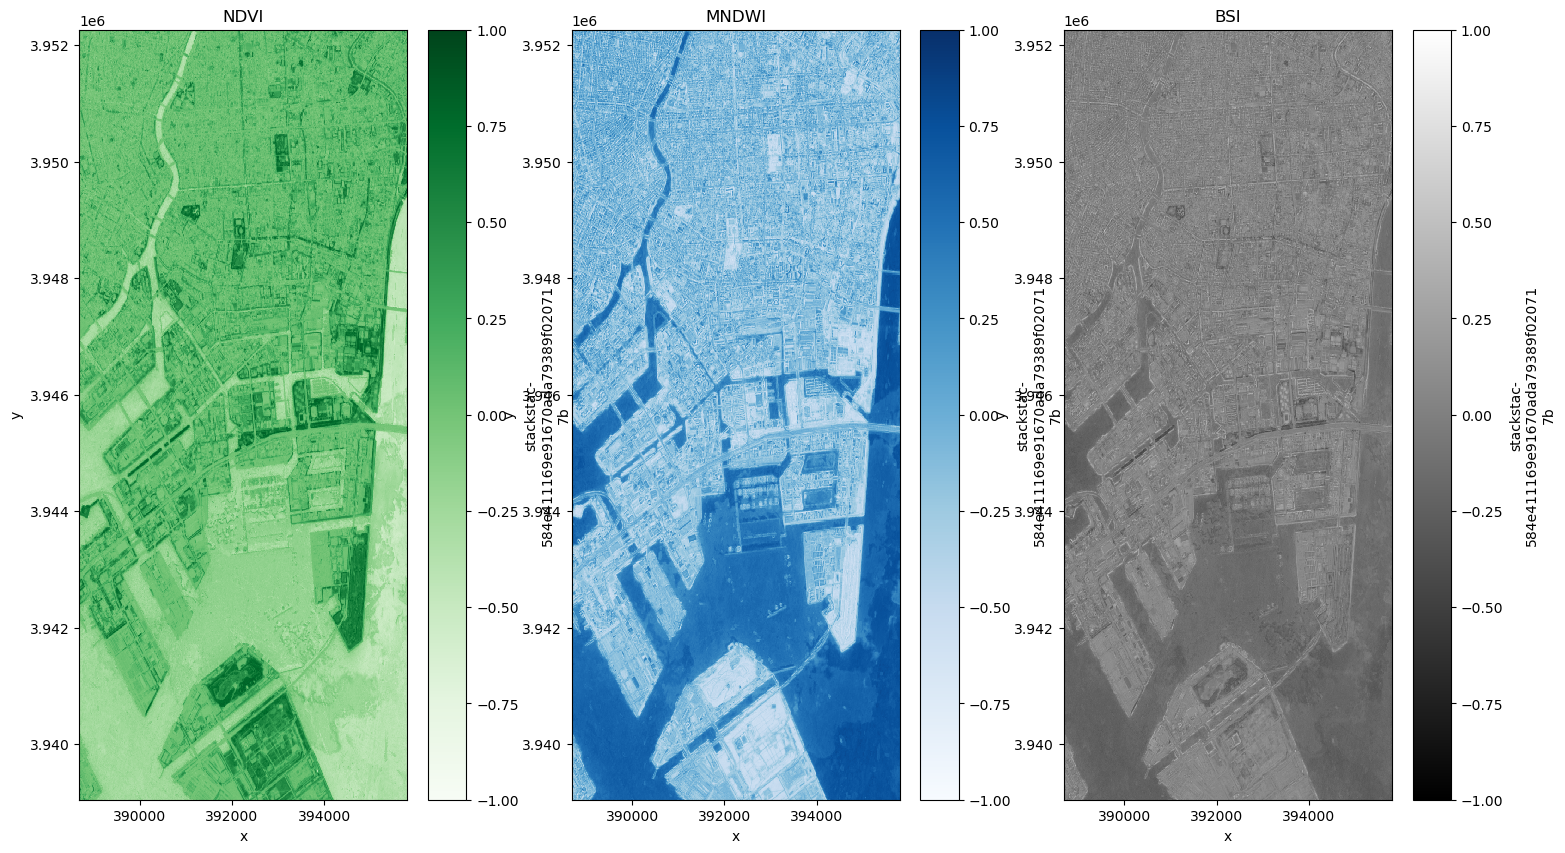

In [9]:
# Extracting bands and calculating land surface indices
blue = composite.sel(band="B02")
green = composite.sel(band="B03")
red = composite.sel(band="B04")
nir = composite.sel(band="B08")
swir1 = composite.sel(band="B11")
swir2 = composite.sel(band="B12")

ndvi = (nir - red) / (nir + red)
mndwi = (green - swir1) / (green + swir1)
ndbi = (swir1 - nir) / (swir1 + nir)
bsi = ((swir1 + red) - (nir + blue)) / ((swir1 + red) + (nir + blue))
#plotting the calculated indices
fig, axes = plt.subplots(1, 3, figsize=(18, 10))

# red.plot.imshow(ax=axes[0], cmap="Reds") # Plotting the Sentinel-2 Red Band showing the urban areas of Koto City
# axes[0].set_title("Sentinel-2 Red Band")


ndvi.plot.imshow(ax=axes[0], cmap="Greens", vmin=-1, vmax=1)
axes[0].set_title("NDVI")

mndwi.plot.imshow(ax=axes[1], cmap="Blues", vmin=-1, vmax=1)
axes[1].set_title("MNDWI")

bsi.plot.imshow(ax=axes[2], cmap="gray", vmin=-1, vmax=1)
axes[2].set_title("BSI");

In [10]:
# Defining training data for land cover classification using Random Forest Classifier
from pyrosm import OSM

osm = OSM("koto.osm.pbf")  # Load the OSM data for Koto City

In [11]:
#Extracting building footprints and water bodies from OSM data
buildings = osm.get_buildings()
landuse = osm.get_landuse()
natural = osm.get_natural()
roads = osm.get_network(network_type="all")

#inspecting the extracted data fclass columns
print(f"Buildings columns: {buildings.columns}")
print(f"Landuse columns: {landuse.columns}")
print(f"Natural columns: {natural.columns}")
print(f"Roads columns: {roads.columns}")

Buildings columns: Index(['addr:city', 'addr:country', 'addr:housenumber', 'addr:housename',
       'addr:postcode', 'addr:place', 'addr:street', 'email', 'name',
       'opening_hours', 'operator', 'phone', 'ref', 'url', 'visible',
       'website', 'building', 'amenity', 'building:flats', 'building:levels',
       'building:material', 'building:min_level', 'building:use', 'craft',
       'height', 'internet_access', 'landuse', 'levels', 'office', 'shop',
       'source', 'start_date', 'wikipedia', 'id', 'timestamp', 'version',
       'tags', 'osm_type', 'geometry', 'changeset'],
      dtype='object')
Landuse columns: Index(['version', 'changeset', 'lon', 'id', 'timestamp', 'tags', 'visible',
       'lat', 'landuse', 'residential', 'geometry', 'osm_type', 'construction',
       'depot', 'industrial', 'port'],
      dtype='object')
Natural columns: Index(['version', 'changeset', 'lon', 'id', 'timestamp', 'tags', 'visible',
       'lat', 'natural', 'geometry', 'osm_type', 'water'],
    

In [12]:
#Assigning training labels based on OSM data for land cover classification
t_buildings = buildings.to_crs("EPSG:32654")[["geometry"]].copy()
t_buildings["class"] = "impervious"

t_vegetation = landuse.to_crs("EPSG:32654")
t_vegetation = t_vegetation[t_vegetation["landuse"].isin(["forest", "grass", "recreation_ground"])]
[["geometry"]].copy()
t_vegetation["class"] = "vegetation"

t_water = natural.to_crs("EPSG:32654")
t_water = t_water[t_water["water"].isin(["water", "river", "stream"])][["geometry"]].copy()
t_water["class"] = "water"

training_polygons = [t_buildings, t_vegetation, t_water]

In [13]:
# Convert roads to the projected CRS and buffer them into polygons, 
# clipping them to the Koto City boundary to create training polygons for the "impervious" class
koto_mask = koto_city.to_crs("EPSG:32654").geometry.union_all()

t_roads = roads.to_crs("EPSG:32654")

road_indices = t_roads.sindex.query(
    koto_mask,
    predicate="intersects"
)

t_roads = t_roads.iloc[road_indices].copy()
t_roads = gpd.clip(t_roads, koto_mask)

t_roads_polygons = t_roads[["geometry"]].copy()
t_roads_polygons["geometry"] = t_roads_polygons.geometry.buffer(3)
t_roads_polygons["class"] = "impervious"

# Soil classification for training data using OSM data, mostly construction sites, farmland, and other soil types. This will be used to train the Random Forest Classifier for land cover classification.
t_soil = landuse.to_crs("EPSG:32654")
t_soil = t_soil[t_soil["landuse"].isin(["construction", "farmland", "brownfield", "allotments"])]
t_soil = t_soil[["geometry"]].copy()
t_soil["class"] = "soil"

In [14]:
#Building a GeoDataFrame for training polygons by concatenating the individual class polygons
training_polygons = [t_buildings, t_vegetation, t_water, t_soil, t_roads_polygons]

training_polygons_gdf = gpd.GeoDataFrame(pd.concat(training_polygons, ignore_index=True), 
    geometry="geometry", crs="EPSG:32654")

In [15]:
# Sampling Sentinel-2 imagery for training data
# by extracting pixel values for each band and the calculated indices

feature_arrays = [blue.values, green.values, red.values, nir.values, swir1.values,
    swir2.values, ndvi.values, mndwi.values, ndbi.values, bsi.values]

image_features = np.stack(feature_arrays, axis=-1)
print(f"Image features shape: {image_features.shape}")

Image features shape: (1322, 712, 10)


In [16]:
from rasterio.features import geometry_mask
from affine import Affine

transform = Affine(float(composite.x[1] - composite.x[0]), 0, float(composite.x[0]),
    0, float(composite.y[1] - composite.y[0]), float(composite.y[0]))

training_features = []
training_labels = []

for _, sample in training_polygons_gdf.iterrows():
    mask = geometry_mask([sample.geometry],out_shape=image_features.shape[:2],
                        transform=transform, invert=True)

    pixels = image_features[mask]
    pixels = pixels[np.isfinite(pixels).all(axis=1)]

    training_features.append(pixels)
    training_labels.extend([sample["class"]] * len(pixels))

training_features = np.vstack(training_features)
training_labels = np.asarray(training_labels)

In [17]:
from rasterio.features import geometry_mask
from rasterio.transform import from_origin

TARGET_CRS = "EPSG:32654"

koto_projected = koto_city.to_crs(TARGET_CRS)
koto_geometry = koto_projected.geometry.union_all()

n_rows, n_cols, n_features = image_features.shape

x_values = composite.x.values
y_values = composite.y.values

x_resolution = abs(float(np.median(np.diff(x_values))))
y_resolution = abs(float(np.median(np.diff(y_values))))

left = float(x_values.min()) - x_resolution / 2
top = float(y_values.max()) + y_resolution / 2

transform = from_origin(
    left,
    top,
    x_resolution,
    y_resolution
)

koto_pixel_mask = geometry_mask(
    [koto_geometry],
    out_shape=(n_rows, n_cols),
    transform=transform,
    invert=True
)

print(koto_pixel_mask.shape)
print(koto_pixel_mask.dtype)

(1322, 712)
bool


In [18]:
#Flattening the image features and using the Boolean mask to filter out pixels outside Koto City
#  for training the Random Forest Classifier
image_features = np.asarray(image_features, dtype=np.float32)
image_features_2d = image_features.reshape(-1, n_features)

inside_koto = koto_pixel_mask.reshape(-1)

valid_image_pixels = (
    inside_koto
    & np.isfinite(image_features_2d).all(axis=1)
)

In [19]:
#Training the Random Forest Classifier using the sampled training data
training_features = np.asarray(training_features, dtype=np.float32)
training_labels = np.asarray(training_labels)

valid_training = np.isfinite(training_features).all(axis=1)

classifier = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

classifier.fit(
    training_features[valid_training],
    training_labels[valid_training]
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [20]:
classified_flat = np.full(
    image_features_2d.shape[0],
    -1,
    dtype=np.int8
)

class_names = np.unique(training_labels[valid_training])
class_to_code = {
    class_name: code
    for code, class_name in enumerate(class_names)
}

predicted_labels = classifier.predict(
    image_features_2d[valid_image_pixels]
)

classified_flat[valid_image_pixels] = np.array(
    [class_to_code[label] for label in predicted_labels],
    dtype=np.int8
)

classified = classified_flat.reshape(n_rows, n_cols)

print(classified.shape)
print(class_to_code)

(1322, 712)
{np.str_('impervious'): 0, np.str_('soil'): 1, np.str_('vegetation'): 2, np.str_('water'): 3}


In [22]:
#Determining resolution of the classified image and calculating the area of each class in square kilometers
x_res = abs(float(composite.x[1] - composite.x[0]))
y_res = abs(float(composite.y[1] - composite.y[0]))
pixel_area_m2 = x_res * y_res
pixel_area_km2 = pixel_area_m2 / 1e6
valid_classified = classified[classified >= 0]

class_counts = pd.Series(valid_classified).value_counts().sort_index()

area_table = pd.DataFrame({
    "class_code": class_counts.index,
    "pixel_count": class_counts.values
})

area_table["class"] = area_table["class_code"].map(
    {code: name for name, code in class_to_code.items()}
)

area_table["area_m2"] = (
    area_table["pixel_count"] * pixel_area_m2
)

area_table["area_km2"] = (
    area_table["area_m2"] / 1_000_000
)

area_table["fraction"] = (
    area_table["area_m2"] /
    area_table["area_m2"].sum()
)

print(area_table)

   class_code  pixel_count       class     area_m2  area_km2  fraction
0           0       344936  impervious  34493600.0   34.4936  0.780964
1           1         5744        soil    574400.0    0.5744  0.013005
2           2        54458  vegetation   5445800.0    5.4458  0.123297
3           3        36542       water   3654200.0    3.6542  0.082734


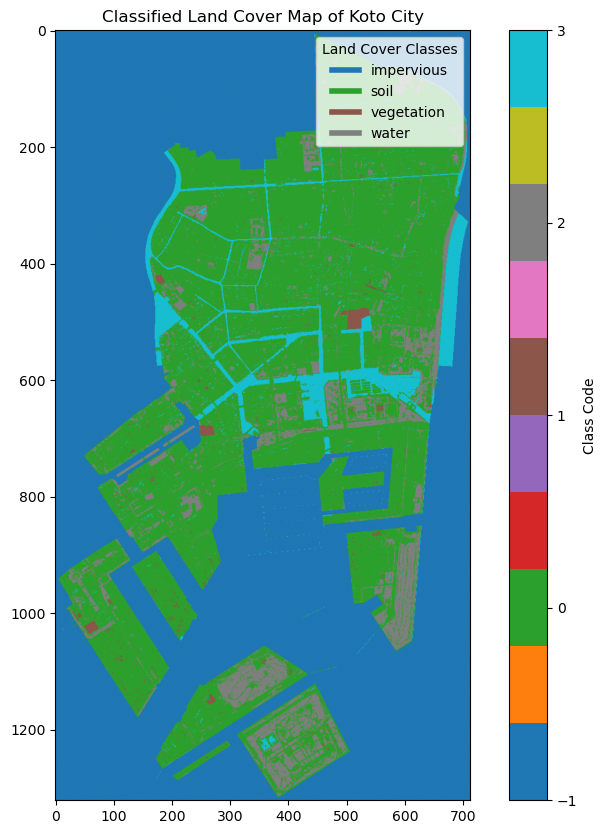

In [23]:
# Plotting the classified land cover map for Koto City
classes = list(class_to_code.keys())


plt.figure(figsize=(10, 10))
plt.imshow(classified, cmap="tab10", vmin=-1, vmax=len(class_to_code)-1)
plt.colorbar(ticks=np.arange(-1, len(class_to_code)), label="Class Code")
plt.title("Classified Land Cover Map of Koto City")
plt.legend(handles=[plt.Line2D([0], [0], color=plt.cm.tab10(i / len(class_to_code)), lw=4, label=cls) for i, cls in enumerate(classes)], title="Land Cover Classes");


In [24]:
transform = Affine(
    float(composite.x[1] - composite.x[0]),
    0,
    float(composite.x[0]),
    0,
    float(composite.y[1] - composite.y[0]),
    float(composite.y[0])
)

In [25]:
from rasterio.features import geometry_mask
from rasterio.transform import from_origin

x_values = composite.x.values
y_values = composite.y.values

x_resolution = abs(float(np.median(np.diff(x_values))))
y_resolution = abs(float(np.median(np.diff(y_values))))

left = float(x_values.min()) - x_resolution / 2
top = float(y_values.max()) + y_resolution / 2

transform = from_origin(
    left,
    top,
    x_resolution,
    y_resolution
)

training_features = []
training_labels = []

for _, sample in training_polygons_gdf.iterrows():
    sample_mask = geometry_mask(
        [sample.geometry],
        out_shape=image_features.shape[:2],
        transform=transform,
        invert=True
    )

    pixels = image_features[sample_mask]
    pixels = pixels[np.isfinite(pixels).all(axis=1)]

    if len(pixels) == 0:
        continue

    training_features.append(pixels)
    training_labels.extend(
        [sample["class"]] * len(pixels)
    )

training_features = np.vstack(training_features).astype(np.float32)
training_labels = np.asarray(training_labels)

print(pd.Series(training_labels).value_counts())

impervious    247275
water          61398
vegetation     14642
soil            5631
Name: count, dtype: int64


In [26]:
rng = np.random.default_rng(42)

labels = np.asarray(training_labels)
class_names = np.unique(labels)

samples_per_class = min(
    np.sum(labels == class_name)
    for class_name in class_names
)

selected_indices = []

for class_name in class_names:
    indices = np.where(labels == class_name)[0]
    selected_indices.extend(
        rng.choice(
            indices,
            size=samples_per_class,
            replace=False
        )
    )

selected_indices = np.asarray(selected_indices)

training_features_balanced = training_features[selected_indices]
training_labels_balanced = labels[selected_indices]

print(pd.Series(training_labels_balanced).value_counts())

impervious    5631
soil          5631
vegetation    5631
water         5631
Name: count, dtype: int64


In [27]:
classifier.fit(
    training_features_balanced,
    training_labels_balanced
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

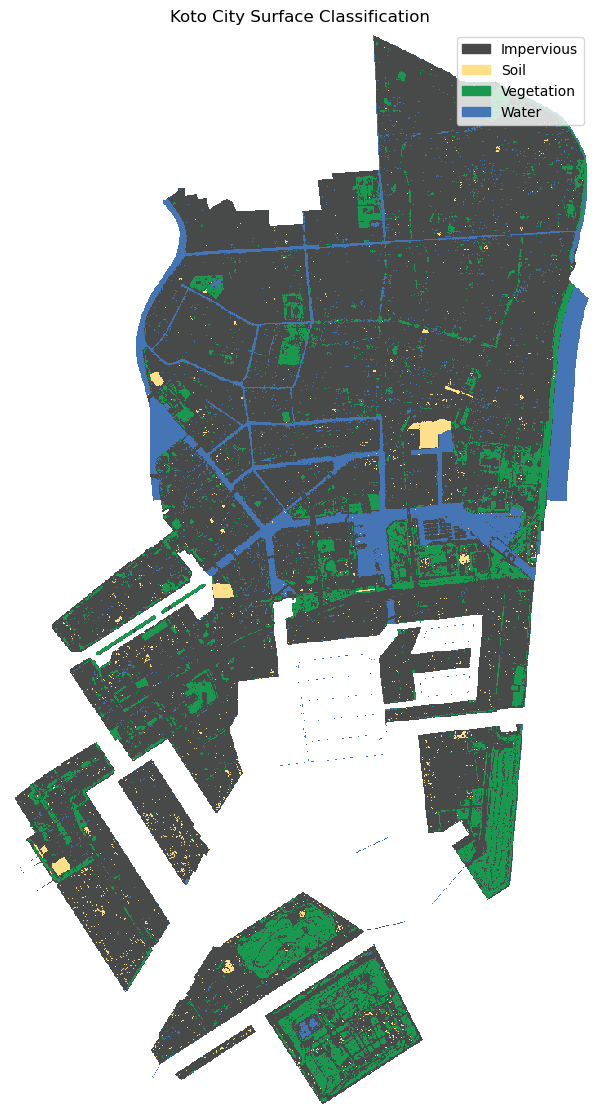

In [28]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

class_colors = {
    "impervious": "#484A4A",
    "vegetation": "#1a9850",
    "water": "#4575b4",
    "soil": "#fee08b"
}

display_array = classified.astype(float)
display_array[display_array < 0] = np.nan

colors = [
    class_colors[class_name]
    for class_name in class_names
]

plt.figure(figsize=(8, 14))
plt.imshow(
    display_array,
    cmap=ListedColormap(colors),
    vmin=0,
    vmax=len(class_names) - 1,
    interpolation="nearest"
)

legend_handles = [
    Patch(
        color=class_colors[class_name],
        label=class_name.title()
    )
    for class_name in class_names
]

plt.legend(
    handles=legend_handles,
    loc="upper right"
)

plt.title("Koto City Surface Classification")
plt.axis("off")
plt.show()

In [29]:
valid_pixels = classified[classified >= 0]

predicted_counts = pd.Series(valid_pixels).value_counts()

predicted_table = pd.DataFrame({
    "class_code": predicted_counts.index,
    "pixel_count": predicted_counts.values
})

predicted_table["class"] = predicted_table["class_code"].map(
    {code: name for name, code in class_to_code.items()}
)

predicted_table["fraction"] = (
    predicted_table["pixel_count"]
    / predicted_table["pixel_count"].sum()
)

print(predicted_table)

   class_code  pixel_count       class  fraction
0           0       344936  impervious  0.780964
1           2        54458  vegetation  0.123297
2           3        36542       water  0.082734
3           1         5744        soil  0.013005


In [30]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

X = training_features_balanced
y = training_labels_balanced

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

classifier = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_val)

print(confusion_matrix(y_val, y_pred, labels=class_names))
print(classification_report(
    y_val,
    y_pred,
    labels=class_names,
    target_names=class_names,
    zero_division=0
))

[[ 745  211  124   46]
 [ 313  706   68   39]
 [  84   40  988   15]
 [  68   35    8 1015]]
              precision    recall  f1-score   support

  impervious       0.62      0.66      0.64      1126
        soil       0.71      0.63      0.67      1126
  vegetation       0.83      0.88      0.85      1127
       water       0.91      0.90      0.91      1126

    accuracy                           0.77      4505
   macro avg       0.77      0.77      0.77      4505
weighted avg       0.77      0.77      0.77      4505



# Water Balance Model

**Water balance modeling for Koto City using the classified land cover data & hydraulic inputs**

Using known inundation levels, estimates for infiltration rates, sewer drainage capacity,and with surface flow towards the nearest water body, we can estimate the potential inundation drainage duration for Koto City after a heavy rainfall event. 

Knowing point data of inundation depth and linearly interpolating between points we can determine the amount of flooded area. Then looking at the distance between the inundation point it can be classified as draining into a waterbody, the sewer or vegetation.

Needing estimates for slope & roughness.

GROUNDWATER ONLY REALLY COMES TO THE SURFACE IN THE FLOODPLAINS OF THE MAJOR RIVERS DURING THE 21-9 TYPHOON, MENTION THIS IN THE RESULTS/DISCUSSION AS A CONSIDERATION FOR THIS MODEL

In [31]:
from matplotlib.colors import Normalize

In [32]:
# Load shinsui kotonaibu and shinsui sumidagawa csv files and only keep relavant points within Koto City boundary
sumidagawa_csv = pd.read_csv("shinsui_sumidagawa.csv")
kotonaibu_csv = pd.read_csv("shinsui_koutounaibu.csv")
combined_csv = pd.concat([sumidagawa_csv, kotonaibu_csv], ignore_index=True)
koto_boundary = koto_city.to_crs(epsg=4326)  # Transform Koto City boundary to WGS84 coordinate reference system

inundation_points = gpd.GeoDataFrame(
    combined_csv,   
    geometry=gpd.points_from_xy(combined_csv['longitude'], combined_csv['latitude']),
    crs='EPSG:4326'
)
inundation_points = inundation_points[inundation_points.within(koto_boundary.geometry.unary_union)]  # Filter points within Koto City boundary

inundation_points = inundation_points.dropna(subset=['Flood depth'])  # Drop rows with NaN depth values

C:\Users\foozd\AppData\Local\Temp\ipykernel_8632\4130820490.py:12: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  inundation_points = inundation_points[inundation_points.within(koto_boundary.geometry.unary_union)]  # Filter points within Koto City boundary


In [33]:
# Load inundation data as WGS84 longitude/latitude points
inundation_data = inundation_points[['longitude', 'latitude', 'Flood depth']].copy()

inundation_gdf = gpd.GeoDataFrame(
    inundation_data,
    geometry=gpd.points_from_xy(inundation_data["longitude"], inundation_data["latitude"],),
    crs="EPSG:4326",)

# Reproject points to the classified image CRS
inundation_gdf = inundation_gdf.to_crs("EPSG:32654")

In [34]:
# Robust outlier removal using the median absolute deviation (MAD).
depth_column = "Flood depth"

inundation_gdf = inundation_gdf.copy()
inundation_gdf[depth_column] = pd.to_numeric(
    inundation_gdf[depth_column],
    errors="coerce"
)

valid_depth = (
    inundation_gdf[depth_column].notna()
    & np.isfinite(inundation_gdf[depth_column])
    & (inundation_gdf[depth_column] > 0)
)

depth_values = inundation_gdf.loc[valid_depth, depth_column]
median_depth = depth_values.median()
mad = np.median(np.abs(depth_values - median_depth))

if mad == 0:
    # Fallback when most observations have exactly the same depth.
    q1, q3 = depth_values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower_limit = max(0, q1 - 1.5 * iqr)
    upper_limit = q3 + 1.5 * iqr

    depth_mask = (
        valid_depth
        & inundation_gdf[depth_column].between(
            lower_limit,
            upper_limit
        )
    )
else:
    robust_z = (
        0.6745
        * (inundation_gdf[depth_column] - median_depth)
        / mad
    )

    # 3.5 is a common conservative MAD threshold.
    depth_mask = valid_depth & (robust_z.abs() <= 3.5)

inundation_clean = inundation_gdf.loc[depth_mask].copy()

print(f"Original points: {len(inundation_gdf)}")
print(f"Retained points: {len(inundation_clean)}")
print(
    inundation_clean[depth_column].describe()
)

Original points: 352343
Retained points: 154635
count    154635.000000
mean          0.366668
std           0.305385
min           0.010000
25%           0.120000
50%           0.290000
75%           0.540000
max           1.320000
Name: Flood depth, dtype: float64


C:\Users\foozd\AppData\Local\Temp\ipykernel_8632\4069823060.py:22: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  koto_boundary = koto_city.geometry.unary_union


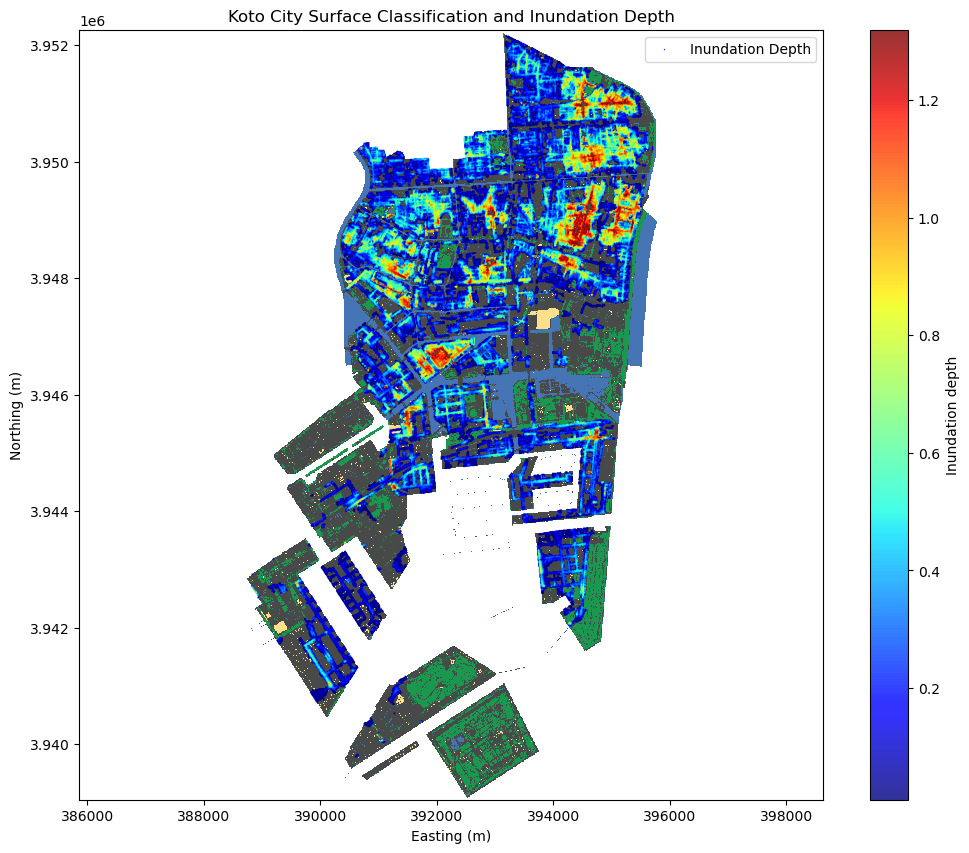

In [35]:
# Plot both datasets in the same projected coordinate system

x_values = composite.x.values
y_values = composite.y.values

x_resolution = abs(float(np.median(np.diff(x_values))))
y_resolution = abs(float(np.median(np.diff(y_values))))

extent = [
    float(x_values.min()) - x_resolution / 2,
    float(x_values.max()) + x_resolution / 2,
    float(y_values.min()) - y_resolution / 2,
    float(y_values.max()) + y_resolution / 2,]


# Match colours to the observed inundation-depth range
depth_min = inundation_clean["Flood depth"].min()
depth_max = inundation_clean["Flood depth"].max()
depth_norm = Normalize(vmin=depth_min, vmax=depth_max)

# Only plotting within the Koto City boundary
koto_boundary = koto_city.geometry.unary_union  
inundation_clean = inundation_clean[inundation_clean.geometry.within(koto_boundary)]

plt.figure(figsize=(12, 10))

plt.imshow(
    display_array,
    cmap=ListedColormap(colors),
    vmin=0,
    vmax=len(class_names) - 1,
    interpolation="nearest",
    extent=extent,
    origin="upper",
)

points = plt.scatter(
    inundation_clean.geometry.x,
    inundation_clean.geometry.y,
    c=inundation_clean["Flood depth"],
    cmap="jet",
    norm=depth_norm,
    s=1,
    alpha=0.8,
    linewidths=0.02,
    label="Inundation Depth",
)

colorbar = plt.colorbar(points)
colorbar.set_label("Inundation depth")

plt.legend()
plt.title("Koto City Surface Classification and Inundation Depth")
plt.xlabel("Easting (m)")
plt.ylabel("Northing (m)")
plt.axis("equal")
plt.show()

In [36]:
#Known/estimated parameters for the drainage areas in Koto City, including area, slope, and roughness coefficient. 

sewer_infiltration_maxcap = 50 #mm/hr any higher the sewer start to overflow.
slope = 1e-4 #Very gentle slope estimate, similar to Dutch river slopes.
rough_manning = 0.03 #Slighlty rougher concrete/asphalt, simulating street furniture.
vegetation_inf = 0.1 #Need to check realistic value
impervious_inf = 0.05 #Need to check realistic value
soil_inf = 0.2 #Need to check realistic value



Retained triangles: 268298
Estimated flooded area: 14,210,255 m²
Estimated flooded area: 14.210 km²
Estimated water volume: 5,562,200.4 m³


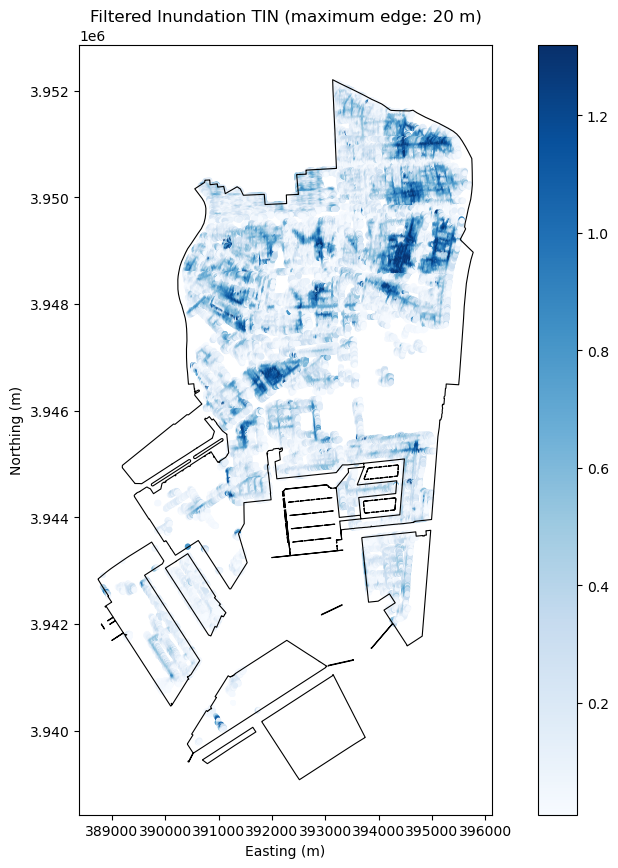

In [40]:
from scipy.spatial import Delaunay
from shapely.geometry import Polygon
from shapely.ops import unary_union

depth_column = "Flood depth"

# Maximum allowed distance between connected points.
max_edge_m = 20

# Set this correctly for your CSV:
# 1.0 if depths are metres, 0.01 if centimetres, 0.001 if millimetres.
depth_to_m = 1.0

points = np.column_stack([
    inundation_clean.geometry.x.to_numpy(),
    inundation_clean.geometry.y.to_numpy()
])

depths = inundation_clean[depth_column].to_numpy()

valid = (
    np.isfinite(points).all(axis=1)
    & np.isfinite(depths)
    & (depths > 0)
)

points = points[valid]
depths = depths[valid]

# Remove duplicate coordinates by averaging their depths.
point_table = pd.DataFrame({
    "x": points[:, 0],
    "y": points[:, 1],
    "depth": depths
})

point_table = (
    point_table
    .groupby(["x", "y"], as_index=False)["depth"]
    .mean()
)

points = point_table[["x", "y"]].to_numpy()
depths = point_table["depth"].to_numpy()

if len(points) < 3:
    raise ValueError("At least three unique inundation points are required.")

# Create the triangulation.
triangulation = Delaunay(points)

triangles = []
triangle_depths = []
triangle_areas = []

for triangle_indices in triangulation.simplices:
    triangle_points = points[triangle_indices]

    # Calculate the lengths of the three triangle edges.
    edge_lengths = np.array([
        np.linalg.norm(triangle_points[0] - triangle_points[1]),
        np.linalg.norm(triangle_points[1] - triangle_points[2]),
        np.linalg.norm(triangle_points[2] - triangle_points[0]),
    ])

    # Reject triangles crossing gaps in the observations.
    if edge_lengths.max() > max_edge_m:
        continue

    polygon = Polygon(triangle_points)

    if not polygon.is_valid or polygon.area <= 0:
        continue

    triangles.append(polygon)
    triangle_depths.append(depths[triangle_indices])
    triangle_areas.append(polygon.area)

if not triangles:
    raise ValueError(
        "No triangles remain. Increase max_edge_m or check the point spacing."
    )

triangle_depths = np.asarray(triangle_depths)
triangle_areas = np.asarray(triangle_areas)

# Combine the retained triangles into the estimated flooded area.
flooded_boundary = unary_union(triangles)
flooded_area_m2 = flooded_boundary.area

# For a linear triangular surface, the volume is:
# triangle area × mean depth at its three vertices.
triangle_mean_depth_m = triangle_depths.mean(axis=1) * depth_to_m
triangle_volumes_m3 = triangle_areas * triangle_mean_depth_m
flooded_volume_m3 = triangle_volumes_m3.sum()

print(f"Retained triangles: {len(triangles)}")
print(f"Estimated flooded area: {flooded_area_m2:,.0f} m²")
print(f"Estimated flooded area: {flooded_area_m2 / 1_000_000:.3f} km²")
print(f"Estimated water volume: {flooded_volume_m3:,.1f} m³")

# Plot the mesh and inundation points.
fig, ax = plt.subplots(figsize=(12, 10))

# from matplotlib.colors import PowerNorm

# depth_values = inundation_clean[depth_column].to_numpy()

# depth_norm = PowerNorm(
#     gamma=0.5,
#     vmin=depth_values.min(),
#     vmax=depth_values.max()
# )

# inundation_clean.plot(
#     ax=ax,
#     column=depth_column,
#     cmap="viridis",
#     norm=depth_norm,
#     legend=True,
#     markersize=8
# )

koto_projected.boundary.plot(ax=ax, color="black", linewidth=0.8)

gpd.GeoSeries(
    triangles,
    crs="EPSG:32654"
).plot(
    ax=ax,
    facecolor="lightblue",
    edgecolor="steelblue",
    linewidth=0.4,
    alpha=0.6
)

inundation_clean.loc[valid].plot(
    ax=ax,
    column=depth_column,
    cmap="Blues",
    legend=True,
    markersize=8
)

ax.set_title(f"Filtered Inundation TIN (maximum edge: {max_edge_m} m)")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")
plt.show()

In [41]:
from rasterio.features import geometry_mask
from rasterio.transform import from_origin
from scipy.integrate import solve_ivp
from shapely.geometry import Point, box
from shapely.ops import unary_union

# Prepare open-water geometry from OSM.
# Buffer line features so nearby flooded areas can reach the water surface.
water_geometries = []

for geometry in t_water.geometry.dropna():
    if geometry.geom_type in {"LineString", "MultiLineString"}:
        water_geometries.append(geometry.buffer(5))
    else:
        water_geometries.append(geometry)

if not water_geometries:
    raise ValueError("No OSM water geometries are available.")

open_water = unary_union(water_geometries).buffer(0)

# koto_bbox is currently WGS84: (min_lon, min_lat, max_lon, max_lat).
# Convert it to a projected polygon in EPSG:32654.
bbox_polygon = (
    gpd.GeoSeries(
        [box(*koto_bbox)],
        crs="EPSG:4326"
    )
    .to_crs("EPSG:32654")
    .iloc[0]
)

# Use the polygons representing the classified/inundated surface.
classified_surface = unary_union(triangles).buffer(0)

# Keep the additional water area inside Koto City.
bbox_inside_koto = bbox_polygon.intersection(koto_geometry)

# Everything inside the BBox but outside the classified surface
# becomes the additional open-water polygon.
additional_open_water = bbox_inside_koto.difference(classified_surface)

# Combine OSM water and the additional water area.
open_water = unary_union([
    open_water,
    additional_open_water
]).buffer(0)

water_connection_distance_m = 20.0

# Raster transform matching `classified`.
raster_transform = from_origin(
    float(x_values.min()) - x_resolution / 2,
    float(y_values.max()) + y_resolution / 2,
    x_resolution,
    y_resolution,
)
class_area_m2 = {
    class_name: 0.0
    for class_name in class_to_code
}

pathway_area_m2 = {
    "surface water": 0.0,
    "sewer": 0.0,
    "soil infiltration": 0.0,
    "vegetation infiltration": 0.0,
}

pathway_volume_m3 = {
    pathway: 0.0
    for pathway in pathway_area_m2
}

for triangle, triangle_depth, triangle_area in zip(
    triangles,
    triangle_depths,
    triangle_areas,
):
    triangle_mask = geometry_mask(
        [triangle],
        out_shape=classified.shape,
        transform=raster_transform,
        invert=True,
    )

    triangle_classes = classified[triangle_mask]
    triangle_classes = triangle_classes[triangle_classes >= 0]

    if len(triangle_classes) == 0:
        dominant_class = "impervious"
    else:
        dominant_code = pd.Series(triangle_classes).mode().iloc[0]
        dominant_class = next(
            name
            for name, code in class_to_code.items()
            if code == dominant_code
        )

    # Always accumulate classified land-cover area.
    class_area_m2[dominant_class] += triangle_area

    mean_depth_m = float(triangle_depth.mean()) * depth_to_m
    triangle_volume_m3 = triangle_area * mean_depth_m

    # Water-connected triangles drain immediately.
    if triangle.centroid.distance(open_water) <= water_connection_distance_m:
        pathway = "surface water"
    else:
        pathway = {
            "impervious": "sewer",
            "soil": "soil infiltration",
            "vegetation": "vegetation infiltration",
            "water": "surface water",
        }.get(dominant_class, "sewer")

    pathway_area_m2[pathway] += triangle_area
    pathway_volume_m3[pathway] += triangle_volume_m3

print("Class areas:")
for class_name, area in class_area_m2.items():
    print(f"{class_name}: {area:,.0f} m²")

print("\nDrainage pathways:")
for pathway in pathway_area_m2:
    print(
        f"{pathway}: "
        f"{pathway_area_m2[pathway]:,.0f} m², "
        f"{pathway_volume_m3[pathway]:,.1f} m³"
    )

Class areas:
impervious: 13,860,793 m²
soil: 53,145 m²
vegetation: 220,598 m²
water: 75,719 m²

Drainage pathways:
surface water: 8,547,080 m², 2,566,763.1 m³
sewer: 5,596,492 m², 2,969,760.6 m³
soil infiltration: 14,594 m², 3,580.9 m³
vegetation infiltration: 52,089 m², 22,095.9 m³


In [42]:
rainfall_intensity_mm_h = 50.0
rainfall_intensity_m_s = rainfall_intensity_mm_h / 1000 / 3600

impervious_runoff_coefficient = 0.9
impervious_to_sewer_fraction = 0.7

sewer_connected_area_m2 = (
    pathway_area_m2["sewer"]
    * impervious_to_sewer_fraction
)

sewer_capacity_m3_s = (
    impervious_runoff_coefficient
    * rainfall_intensity_m_s
    * sewer_connected_area_m2
)

print(f"Sewer-assigned area: {pathway_area_m2['sewer']:,.0f} m²")
print(f"Sewer-connected area: {sewer_connected_area_m2:,.0f} m²")
print(f"Estimated sewer capacity: {sewer_capacity_m3_s:.4f} m³/s")

Sewer-assigned area: 5,596,492 m²
Sewer-connected area: 3,917,545 m²
Estimated sewer capacity: 48.9693 m³/s


In [43]:
#Post peak rainfall intensity decay function for the rainfall event
from scipy.interpolate import PchipInterpolator

# Time in seconds, measured from the start of the event.
rainfall_time_s = np.array([
    0,
    600,      # 10 minutes: peak ends
    1800,     # 30 minutes
    7200,     # 2 hours
    21600     # 6 hours
])

rainfall_intensity_mm_h = np.array([
    153,
    153,
    50,
    30,
    0
])

rainfall_function = PchipInterpolator(
    rainfall_time_s,
    rainfall_intensity_mm_h,
    extrapolate=False
)

def rainfall_intensity(time_s):
    time_s = np.asarray(time_s, dtype=float)

    intensity = np.interp(
        time_s,
        rainfall_time_s,
        rainfall_intensity_mm_h,
        left=rainfall_intensity_mm_h[0],
        right=0.0
    )

    return np.maximum(intensity, 0.0)

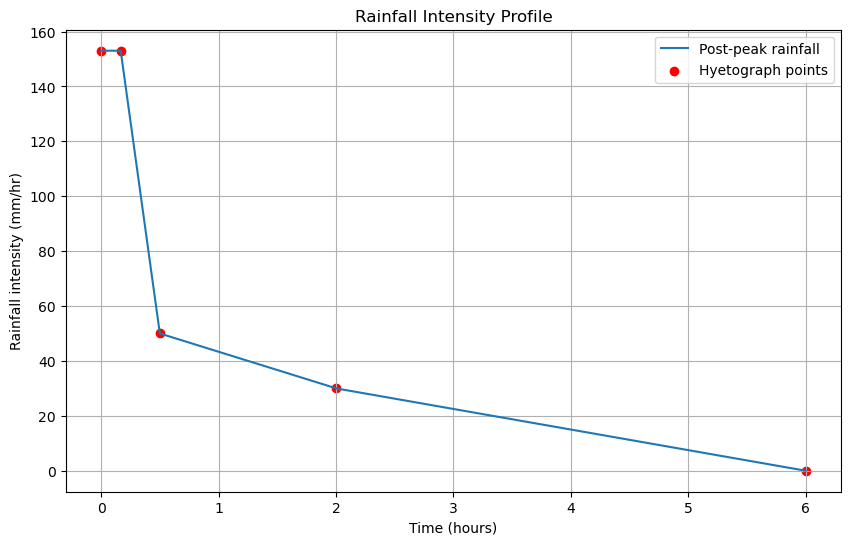

In [44]:
time_sim = np.linspace(0, 21600, 1000)

plt.figure(figsize=(10, 6))
plt.plot(
    time_sim / 3600,
    rainfall_intensity(time_sim),
    label="Post-peak rainfall"
)
plt.scatter(
    rainfall_time_s / 3600,
    rainfall_intensity_mm_h,
    color="red",
    label="Hyetograph points"
)
plt.xlabel("Time (hours)")
plt.ylabel("Rainfall intensity (mm/hr)")
plt.title("Rainfall Intensity Profile")
plt.grid(True)
plt.legend()
plt.show()

In [45]:
def estimate_drainage_time(
    pathway_volume_m3,
    pathway_area_m2,
    sewer_capacity_m3_s,
    infiltration_rates_mm_h,
    rainfall_function,
    runoff_coefficients=None,
    target_depth_mm=10,
    duration_h=168,
):
    total_volume_m3 = sum(pathway_volume_m3.values())
    surface_water_volume_m3 = pathway_volume_m3.get(
        "surface water",
        0.0
    )

    remaining_volume_m3 = total_volume_m3 - surface_water_volume_m3
    remaining_area_m2 = (
        sum(pathway_area_m2.values())
        - pathway_area_m2.get("surface water", 0.0)
    )

    if remaining_volume_m3 <= 0:
        return 0.0, pd.DataFrame(), {}

    infiltration_m_s = {
        name: rate / 1000 / 3600
        for name, rate in infiltration_rates_mm_h.items()
    }

    if runoff_coefficients is None:
        runoff_coefficients = {
            "impervious": 0.9,
            "soil": 0.2,
            "vegetation": 0.1,
        }

    target_volume_m3 = remaining_area_m2 * target_depth_mm / 1000

    def drainage_rate(time_s, state):
        volume_m3 = max(float(state[0]), 0.0)

        if volume_m3 <= target_volume_m3:
            return [0.0]

        rainfall_mm_h = float(rainfall_function(time_s))
        rainfall_m_s = rainfall_mm_h / 1000 / 3600

        # Rainfall-generated runoff entering the drainage system.
        q_runoff = (
            pathway_area_m2.get("sewer", 0.0)
            * runoff_coefficients["impervious"]
            * rainfall_m_s
        )

        # Infiltration is limited by both soil capacity and rainfall.
        q_infiltration_capacity = (
            pathway_area_m2.get("soil infiltration", 0.0)
            * infiltration_m_s.get("soil", 0.0)
            + pathway_area_m2.get("vegetation infiltration", 0.0)
            * infiltration_m_s.get("vegetation", 0.0)
        )

        q_infiltration_rainfall = (
            pathway_area_m2.get("soil infiltration", 0.0)
            + pathway_area_m2.get("vegetation infiltration", 0.0)
        ) * rainfall_m_s

        q_infiltration = min(
            q_infiltration_capacity,
            q_infiltration_rainfall
        )

        # This should represent sewer drainage capacity, not rainfall runoff.
        q_sewer_out = max(float(sewer_capacity_m3_s), 0.0)

        # Positive rainfall input, negative drainage output.
        return [
            q_runoff - q_sewer_out - q_infiltration
        ]

    def reached_target(time_s, state):
        return state[0] - target_volume_m3

    reached_target.terminal = True
    reached_target.direction = -1

    solution = solve_ivp(
        drainage_rate,
        t_span=(0, duration_h * 3600),
        y0=[remaining_volume_m3],
        events=reached_target,
        max_step=300,
    )

    if len(solution.t_events[0]) == 0:
        drainage_time_h = np.nan
    else:
        drainage_time_h = solution.t_events[0][0] / 3600

    result = pd.DataFrame({
        "time_h": solution.t / 3600,
        "volume_m3": solution.y[0],
        "depth_mm": solution.y[0] / remaining_area_m2 * 1000,
        "rainfall_mm_h": rainfall_function(solution.t),
    })

    return drainage_time_h, result, {
        "surface_water_m3": surface_water_volume_m3,
        "sewer_outflow_m3_s": sewer_capacity_m3_s,
    }

In [47]:
print("Depth statistics:")
print(inundation_clean[depth_column].describe())

print("\nClass areas:")
print(pd.Series(class_area_m2))

print("\nArea check:")
print(f"Flooded area: {flooded_area_m2:,.1f} m²")
print(f"Class-area total: {sum(class_area_m2.values()):,.1f} m²")
print(
    f"Class-area ratio: "
    f"{sum(class_area_m2.values()) / flooded_area_m2:.3f}"
)

print("\nTIN volume check:")
print(f"Volume: {flooded_volume_m3:,.1f} m³")
print(
    f"Mean depth: "
    f"{flooded_volume_m3 / flooded_area_m2:.4f} m"
)

Depth statistics:
count    154635.000000
mean          0.366668
std           0.305385
min           0.010000
25%           0.120000
50%           0.290000
75%           0.540000
max           1.320000
Name: Flood depth, dtype: float64

Class areas:
impervious    1.386079e+07
soil          5.314480e+04
vegetation    2.205981e+05
water         7.571904e+04
dtype: float64

Area check:
Flooded area: 14,210,255.4 m²
Class-area total: 14,210,255.4 m²
Class-area ratio: 1.000

TIN volume check:
Volume: 5,562,200.4 m³
Mean depth: 0.3914 m


In [48]:
drainage_time_h, drainage_result, pathway_capacity = (
    estimate_drainage_time(
        pathway_volume_m3=pathway_volume_m3,
        pathway_area_m2=pathway_area_m2,
        sewer_capacity_m3_s=sewer_capacity_m3_s,
        infiltration_rates_mm_h={
            "soil": soil_inf,
            "vegetation": vegetation_inf,
        },
        rainfall_function=rainfall_intensity,
        target_depth_mm=10,
    )
)

drainage_rate_m3_s = drainage_result["volume_m3"].diff() / drainage_result["time_h"].diff() / 3600
print("\nDrainage rate (m³/s):")
print(np.abs(drainage_rate_m3_s.mean()))
print(f"Estimated drainage time to 10 mm depth: {drainage_time_h:.2f} hours")
print("\nPathway capacities:")
for pathway, capacity in pathway_capacity.items():
    print(f"{pathway}: {capacity:,.4f} m³/s")
print("\nDrainage result head:")
print(drainage_result.head())


Drainage rate (m³/s):
35.40639075365984
Estimated drainage time to 10 mm depth: 21.79 hours

Pathway capacities:
surface_water_m3: 2,566,763.1094 m³/s
sewer_outflow_m3_s: 48.9693 m³/s

Drainage result head:
     time_h     volume_m3    depth_mm  rainfall_mm_h
0  0.000000  2.995437e+06  528.932454          153.0
1  0.000197  2.995555e+06  528.953176          153.0
2  0.002172  2.996728e+06  529.160389          153.0
3  0.021916  3.008463e+06  531.232522          153.0
4  0.105250  3.057991e+06  539.978194          153.0


In [49]:
# Save the drainage result to a CSV file for further analysis.
drainage_result.to_csv("koto_drainage_simulation.csv", index=False)

<Axes: >

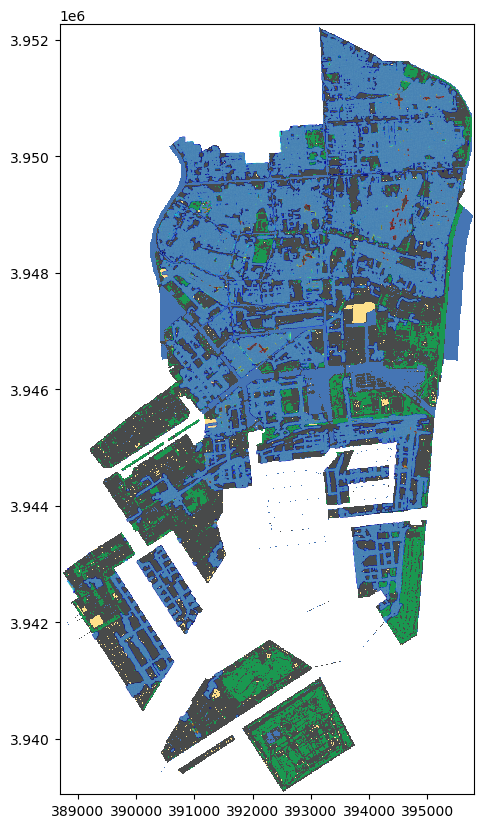

In [50]:
#Plotting Koto City classified land cover map with the estimated flooded area and drainage pathways
plt.figure(figsize=(12, 10))
plt.imshow(
    display_array,
    cmap=ListedColormap(colors),
    vmin=0,
    vmax=len(class_names) - 1,
    interpolation="nearest",
    extent=extent,
    origin="upper",
)

plt.scatter(
    inundation_clean.geometry.x,
    inundation_clean.geometry.y,
    c=inundation_clean[depth_column],
    cmap="jet",
    norm=depth_norm,
    s=1,
    alpha=0.8,
    linewidths=0.02,
    label="Inundation Depth",
)

gpd.GeoSeries(
    triangles,
    crs="EPSG:32654"
).plot(
    ax=plt.gca(),
    facecolor="lightblue",
    edgecolor="steelblue",
    linewidth=0.4,
    alpha=0.6,
    label="Estimated Flooded Area"
)

In [51]:
pathway_area_m2_total = (
    sum(pathway_area_m2.values())
    - pathway_area_m2.get("surface water", 0.0)
)

drainage_result["net_drainage_rate_pw_mm_h"] = (
    -drainage_result["volume_m3"].diff()
    / drainage_result["time_h"].diff()
    / pathway_area_m2_total
    * 1000
)

drainage_result["net_drainage_rate_fa_mm_h"] = (
    -drainage_result["volume_m3"].diff()
    / drainage_result["time_h"].diff()
    / flooded_area_m2
    * 1000
)

infiltration_m_s = {
    name: rate / 1000 / 3600
    for name, rate in {
        "soil": soil_inf,
        "vegetation": vegetation_inf,
    }.items()
}

q_infiltration_capacity = (
    pathway_area_m2.get("soil infiltration", 0.0)
    * infiltration_m_s["soil"]
    + pathway_area_m2.get("vegetation infiltration", 0.0)
    * infiltration_m_s["vegetation"]
)

drainage_result["actual_drainage_rate_mm_h"] = (
    (
        pathway_capacity["sewer_outflow_m3_s"]
        + q_infiltration_capacity
    )
    / pathway_area_m2_total
    * 3600
    * 1000
)

print("\nAverage drainage rate (per pathway area):")
print(drainage_result["net_drainage_rate_pw_mm_h"].mean())

print("\nAverage drainage rate (per flooded area):")
print(drainage_result["net_drainage_rate_fa_mm_h"].mean())


Average drainage rate (per pathway area):
22.507338169466934

Average drainage rate (per flooded area):
8.969789995356962
